# 6장. 데이터를 보며 질문을 만드는 EDA

이 노트북은 `book/chapters/ch06_eda_questions.md` 강의안을 초보자가 그대로 따라 하며 이해할 수 있도록 구성한 실습 자료입니다.

이번 장의 핵심은 그래프나 표를 많이 만드는 것이 아니라, 데이터를 보며 현재 데이터로 답할 수 있는 질문을 만들고 그 질문을 지표와 코드로 연결하는 것입니다.


## 0. 이 노트북 사용 방법

아래 셀을 위에서부터 차례대로 실행하세요.

- 이 노트북은 5장에서 만든 `data/processed/*_clean.csv` 파일을 사용합니다.
- 전처리 파일이 없다면 먼저 `python scripts/preprocess_data.py`를 실행하세요.
- EDA 결과표는 `reports/` 폴더에 CSV와 Markdown 보고서로 저장합니다.
- EDA 결과는 최종 결론이 아니라, 다음 분석 질문을 만드는 중간 산출물입니다.


## 1. EDA는 결론보다 질문에 가깝다

EDA는 Exploratory Data Analysis, 즉 탐색적 데이터 분석입니다. 이름 그대로 데이터를 여러 방향에서 탐색하면서 분포, 패턴, 차이, 관계, 이상한 값을 발견하는 과정입니다.

EDA에서 자주 던지는 질문은 다음과 같습니다.

- 데이터는 어떤 변수들로 구성되어 있는가?
- 주요 숫자형 변수의 분포는 어떤가?
- 주요 범주형 변수의 빈도는 어떤가?
- 특정 그룹 간 차이가 있는가?
- 시간에 따른 변화가 있는가?
- 이상하게 큰 값이나 작은 값이 있는가?
- 다음 단계에서 더 깊이 볼 질문은 무엇인가?


## 2. 관찰, 가설, 결론 구분하기

EDA 결과를 해석할 때는 관찰, 가설, 결론을 구분해야 합니다.

| 구분 | 의미 | 예시 |
|---|---|---|
| 관찰 | 데이터에서 직접 확인한 사실 | 전자기기 카테고리의 매출 비중이 가장 높다 |
| 가설 | 관찰을 바탕으로 생각해 볼 가능성 | 전자기기는 단가가 높아 매출 비중이 클 수 있다 |
| 결론 | 추가 검증 후 말할 수 있는 판단 | 단가와 판매 수량을 함께 분석한 결과 매출 차이의 주요 요인은 단가였다 |

이번 장에서는 주로 관찰과 가설을 만들고, 다음 분석 질문으로 연결하는 연습을 합니다.


## 3. 좋은 분석 질문의 조건

좋은 분석 질문은 데이터로 답할 수 있어야 합니다.

| 조건 | 설명 | 예시 |
|---|---|---|
| 데이터 기반 | 현재 데이터로 답할 수 있어야 함 | 월별 매출은 어떻게 변하는가? |
| 구체적 | 분석 대상과 기준이 명확해야 함 | 카테고리별 매출 비중은 어떻게 다른가? |
| 측정 가능 | 지표로 계산할 수 있어야 함 | 주문 수, 총매출, 평균 구매 금액 |
| 해석 가능 | 결과가 다음 판단과 연결되어야 함 | 어떤 상품군을 더 자세히 봐야 하는가? |
| 검증 가능 | 코드로 확인할 수 있어야 함 | `groupby()`로 계산 가능 |


## 4. 패키지와 경로 설정

노트북이 `notebooks/` 폴더 안에서 실행되는 경우와 프로젝트 루트에서 실행되는 경우를 모두 고려해 경로를 설정합니다.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np

CURRENT_DIR = Path.cwd()
files = ['customers_clean.csv', 'products_clean.csv', 'orders_clean.csv', 'order_items_clean.csv']

# 일반적인 프로젝트 구조(data/processed)와 노트북 옆에 CSV가 있는 경우를 모두 고려한다.
candidates = [
    (CURRENT_DIR / 'data' / 'processed', CURRENT_DIR),
    (CURRENT_DIR, CURRENT_DIR),
    (CURRENT_DIR.parent / 'data' / 'processed', CURRENT_DIR.parent),
    (CURRENT_DIR.parent, CURRENT_DIR.parent),
]
found = next(((path, root) for path, root in candidates
              if all((path / filename).is_file() for filename in files)), None)
if found is None:
    raise FileNotFoundError('customers/products/orders/order_items_clean.csv 4개를 현재 폴더 또는 data/processed에 놓아주세요.')

PROCESSED_DIR, PROJECT_ROOT = found
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('현재 실행 위치:', CURRENT_DIR)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('보고서 폴더:', REPORT_DIR)


현재 실행 위치: /mnt/data
전처리 데이터 폴더: /mnt/data
보고서 폴더: /mnt/data/reports


## 5. 전처리된 데이터 불러오기

6장은 5장에서 저장한 전처리 데이터를 사용합니다. 전처리 파일이 없다면 먼저 아래 명령을 터미널에서 실행하세요.

```bash
python scripts/preprocess_data.py
```


In [2]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'products_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]

if missing_files:
    for path in missing_files:
        print('누락 파일:', path)
    raise FileNotFoundError('전처리 파일이 없습니다. 먼저 python scripts/preprocess_data.py 를 실행하세요.')

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('전처리 데이터 불러오기 완료')


전처리 데이터 불러오기 완료


## 6. 데이터 크기와 컬럼 확인하기

EDA를 시작하기 전에 각 데이터의 행/열 수와 컬럼명을 다시 확인합니다. CSV로 저장했다가 다시 불러오면 날짜 컬럼이 문자열로 돌아올 수 있으므로 날짜형 변환도 다시 확인합니다.


In [3]:
data = {
    'customers': customers,
    'products': products,
    'orders': orders,
    'order_items': order_items,
}

for name, df in data.items():
    print(f'[{name}]')
    print('shape:', df.shape)
    print('columns:', list(df.columns))
    print()


[customers]
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']

[products]
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']

[orders]
shape: (300, 7)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status', 'order_month', 'order_dayofweek']

[order_items]
shape: (764, 6)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'line_total']



In [4]:
orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')

if 'signup_date' in customers.columns:
    customers['signup_date'] = pd.to_datetime(customers['signup_date'], errors='coerce')

if 'order_month' not in orders.columns:
    orders['order_month'] = orders['order_date'].dt.to_period('M').astype(str)

print('order_date 변환 실패:', orders['order_date'].isna().sum())
print('주문 시작일:', orders['order_date'].min())
print('주문 종료일:', orders['order_date'].max())


order_date 변환 실패: 0
주문 시작일: 2025-09-12 00:00:00
주문 종료일: 2026-09-11 00:00:00


## 7. 분석 질문을 먼저 표로 정리하기

EDA를 시작하기 전에 어떤 질문을 볼지 먼저 표로 정리하면 분석이 산만해지지 않습니다. 아래 표는 고객, 상품, 주문, 매출, 시간, 고객 가치 관점에서 만들 수 있는 기본 질문입니다.


In [5]:
questions = pd.DataFrame({
    'analysis_area': ['고객', '상품', '주문', '매출', '시간', '고객 가치'],
    'question': [
        '고객은 어떤 지역과 연령대에 분포하는가?',
        '어떤 카테고리의 상품이 많은가?',
        '주문 상태와 결제수단 분포는 어떤가?',
        '카테고리별 매출은 어떻게 다른가?',
        '월별 매출과 주문 수는 어떻게 변하는가?',
        '구매 금액이 높은 고객은 누구인가?',
    ],
    'metric': [
        '고객 수, 평균 나이',
        '카테고리별 상품 수',
        '주문 수, 비율',
        '총매출, 매출 비중',
        '월별 매출, 월별 주문 수',
        '고객별 총매출, 주문 횟수',
    ],
    'required_data': [
        'customers',
        'products',
        'orders',
        'order_items, products',
        'orders, order_items',
        'customers, orders, order_items',
    ],
})

questions


,analysis_area,question,metric,required_data
0,고객,고객은 어떤 지역과 연령대에 분포하는가?,"고객 수, 평균 나이",customers
1,상품,어떤 카테고리의 상품이 많은가?,카테고리별 상품 수,products
2,주문,주문 상태와 결제수단 분포는 어떤가?,"주문 수, 비율",orders
3,매출,카테고리별 매출은 어떻게 다른가?,"총매출, 매출 비중","order_items, products"
4,시간,월별 매출과 주문 수는 어떻게 변하는가?,"월별 매출, 월별 주문 수","orders, order_items"
5,고객 가치,구매 금액이 높은 고객은 누구인가?,"고객별 총매출, 주문 횟수","customers, orders, order_items"


## 8. 고객 데이터 EDA

먼저 고객 데이터만 따로 살펴봅니다. 하나의 데이터셋 안에서 분포와 빈도를 확인하면 이후 병합 분석을 할 때 기준이 생깁니다.

고객 데이터에서 이어질 수 있는 질문은 다음과 같습니다.

- 고객은 어느 도시에 많이 분포하는가?
- 고객의 평균 나이는 어느 정도인가?
- 성별 고객 수는 어떻게 분포하는가?
- 도시별 구매 금액도 차이가 있는가?

In [6]:
customers['age'].describe()


count    150.000000
mean      42.086667
std       15.613166
min       19.000000
25%       29.000000
50%       40.000000
75%       57.000000
max       69.000000
Name: age, dtype: float64

In [7]:
customer_city = customers['city'].value_counts(dropna=False).reset_index()
customer_city.columns = ['city', 'customer_count']
customer_city['customer_ratio'] = (
    customer_city['customer_count'] / customer_city['customer_count'].sum() * 100
).round(2)

customer_city


,city,customer_count,customer_ratio
0,성남,21,14.00
1,광주,17,11.33
2,부산,16,10.67
3,대구,15,10.00
4,서울,15,10.00
5,울산,14,9.33
6,인천,14,9.33
7,대전,14,9.33
8,수원,13,8.67
9,고양,11,7.33


In [8]:
customer_gender = customers['gender'].value_counts(dropna=False).reset_index()
customer_gender.columns = ['gender', 'customer_count']
customer_gender['customer_ratio'] = (
    customer_gender['customer_count'] / customer_gender['customer_count'].sum() * 100
).round(2)

customer_gender


,gender,customer_count,customer_ratio
0,F,84,56.0
1,M,66,44.0


## 9. 상품 데이터 EDA

상품 데이터에서는 카테고리와 가격을 먼저 봅니다. 상품 수가 많은 카테고리가 매출도 높은지는 아직 알 수 없습니다. 그것은 주문 상세와 연결한 뒤 확인해야 합니다.


In [9]:
product_category = products['category'].value_counts(dropna=False).reset_index()
product_category.columns = ['category', 'product_count']
product_category['product_ratio'] = (
    product_category['product_count'] / product_category['product_count'].sum() * 100
).round(2)

product_category


,category,product_count,product_ratio
0,스포츠,19,19.0
1,전자기기,17,17.0
2,생활용품,16,16.0
3,뷰티,16,16.0
4,도서,14,14.0
5,패션,11,11.0
6,식품,7,7.0


In [10]:
products['price'].describe()


count       100.000000
mean     110040.000000
std       56433.910574
min        5000.000000
25%       65750.000000
50%      112000.000000
75%      161000.000000
max      200000.000000
Name: price, dtype: float64

In [11]:
category_price = (
    products
    .groupby('category', as_index=False)
    .agg(
        product_count=('product_id', 'count'),
        avg_price=('price', 'mean'),
        min_price=('price', 'min'),
        max_price=('price', 'max'),
    )
    .assign(avg_price=lambda df: df['avg_price'].round(0))
    .sort_values('avg_price', ascending=False)
)

category_price


,category,product_count,avg_price,min_price,max_price
4,식품,7,137143.0,67000,197000
1,뷰티,16,117688.0,5000,200000
6,패션,11,115909.0,28000,198000
3,스포츠,19,111579.0,10000,196000
0,도서,14,106857.0,25000,174000
5,전자기기,17,101588.0,5000,165000
2,생활용품,16,96438.0,11000,188000


## 10. 주문 데이터 EDA

주문 데이터에서는 주문 상태, 결제수단, 주문 기간을 확인합니다. 주문 상태 분포는 이후 매출 분석에서 완료 주문만 볼지, 전체 주문을 볼지 결정하는 기준이 됩니다.


In [12]:
order_status = orders['order_status'].value_counts(dropna=False).reset_index()
order_status.columns = ['order_status', 'order_count']
order_status['order_ratio'] = (
    order_status['order_count'] / order_status['order_count'].sum() * 100
).round(2)

order_status


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


In [13]:
payment_method = orders['payment_method'].value_counts(dropna=False).reset_index()
payment_method.columns = ['payment_method', 'order_count']
payment_method['order_ratio'] = (
    payment_method['order_count'] / payment_method['order_count'].sum() * 100
).round(2)

payment_method


,payment_method,order_count,order_ratio
0,kakao_pay,79,26.33
1,naver_pay,77,25.67
2,bank_transfer,74,24.67
3,card,70,23.33


In [14]:
print('주문 시작일:', orders['order_date'].min())
print('주문 종료일:', orders['order_date'].max())
print('주문 월 개수:', orders['order_month'].nunique())


주문 시작일: 2025-09-12 00:00:00
주문 종료일: 2026-09-11 00:00:00
주문 월 개수: 13


## 11. 매출 분석을 위한 데이터 연결

카테고리별 매출을 계산하려면 주문 상세와 상품 정보를 `product_id` 기준으로 연결해야 합니다. 병합 후에는 행 수와 누락 여부를 반드시 확인합니다.

이번 장의 금액 집계에서는 `completed` 주문에 포함된 상세 행만 사용한다.


In [15]:
if 'line_total' not in order_items.columns:
    order_items['line_total'] = order_items['quantity'] * order_items['unit_price']

order_items[['quantity', 'unit_price', 'line_total']].head()


,quantity,unit_price,line_total
0,3,102000,306000
1,5,25000,125000
2,3,142000,426000
3,3,193000,579000
4,4,189000,756000


In [16]:
# 금액성 EDA는 완료 주문만 사용한다. 먼저 주문 상태를 붙일 때 행 수가 불어나지 않는지 확인한다.
status_join = order_items.merge(
    orders[['order_id', 'order_status']], on='order_id', how='left',
    validate='many_to_one', indicator=True,
)
assert len(status_join) == len(order_items), '주문 상태 병합 과정에서 행 수가 변경되었습니다.'
assert status_join['_merge'].eq('both').all(), 'order_id가 주문 테이블에 없는 상세 행이 있습니다.'
completed_items = status_join.loc[
    status_join['order_status'].eq('completed')
].drop(columns='_merge').copy()

sales_items = completed_items.merge(
    products[['product_id', 'product_name', 'category', 'price']],
    on='product_id', how='left', validate='many_to_one', indicator=True,
)
assert len(sales_items) == len(completed_items)
assert sales_items['_merge'].eq('both').all(), '상품 정보가 없는 행이 있습니다.'
sales_items = sales_items.drop(columns='_merge')
source_total = int(completed_items['line_total'].sum())

print('전체 주문 상세 행:', len(order_items))
print('completed 주문 상세 행:', len(completed_items))
print('상품 병합 후 행:', len(sales_items))
print('completed 기준 금액:', f'{source_total:,}원')
sales_items.head()


전체 주문 상세 행: 764
completed 주문 상세 행: 474
상품 병합 후 행: 474
completed 기준 금액: 148,990,000원


,order_item_id,order_id,product_id,quantity,unit_price,line_total,order_status,product_name,category,price
0,1,1,100,3,102000,306000,completed,도서 상품 100,도서,102000
1,2,1,87,5,25000,125000,completed,도서 상품 087,도서,25000
2,3,1,7,3,142000,426000,completed,도서 상품 007,도서,142000
3,4,1,9,3,193000,579000,completed,스포츠 상품 009,스포츠,193000
4,13,6,83,3,24000,72000,completed,전자기기 상품 083,전자기기,24000


## 12. 카테고리별 매출 EDA

카테고리별 completed 주문 금액은 어떤 상품군이 매출에 많이 기여했는지 보여 줍니다. 다만 매출이 높은 이유가 판매 수량 때문인지, 단가 때문인지는 추가로 확인해야 합니다.

해석 예시:

> 관찰: 매출 비중이 높은 카테고리가 존재합니다.
> 가설: 해당 카테고리는 판매 수량이 많거나 평균 단가가 높아서 매출이 클 수 있습니다.
> 추가 분석: 카테고리별 판매 수량과 평균 단가를 함께 비교해야 합니다.

In [17]:
category_sales = (
    sales_items
    .groupby('category', as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

category_sales['sales_ratio'] = (
    category_sales['total_sales'] / category_sales['total_sales'].sum() * 100
).round(2)

category_sales


,category,total_quantity,total_sales,sales_ratio
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
0,도서,149,16389000,11.00
6,패션,111,10587000,7.11


In [18]:
category_sales_with_price = category_sales.merge(
    category_price[['category', 'avg_price']],
    on='category',
    how='left',
)

category_sales_with_price


,category,total_quantity,total_sales,sales_ratio,avg_price
0,스포츠,295,31743000,21.31,111579.0
1,전자기기,259,26400000,17.72,101588.0
2,생활용품,272,23915000,16.05,96438.0
3,뷰티,223,23383000,15.69,117688.0
4,식품,133,16573000,11.12,137143.0
5,도서,149,16389000,11.00,106857.0
6,패션,111,10587000,7.11,115909.0


## 13. 월별 매출과 주문 수 EDA

월별 completed 주문 금액을 보려면 주문 상세와 주문 정보를 `order_id` 기준으로 연결합니다. 월별 매출은 시간 흐름을 보여 주지만, 원인을 바로 설명하지는 않습니다.

월별 매출이 특정 월에 높아졌다면 바로 원인을 단정하지 말고, 주문 수가 늘었는지 평균 주문 금액이 늘었는지, 특정 카테고리 매출이 늘었는지 추가로 확인해야 합니다.

In [19]:
order_sales_all = order_items.merge(
    orders, on='order_id', how='left', validate='many_to_one', indicator=True,
)
assert len(order_sales_all) == len(order_items)
assert order_sales_all['_merge'].eq('both').all(), '없는 order_id가 있습니다.'
order_sales = order_sales_all.loc[
    order_sales_all['order_status'].eq('completed')
].drop(columns='_merge').copy()
order_sales['order_date'] = pd.to_datetime(order_sales['order_date'], errors='coerce')
order_sales['order_month'] = order_sales['order_date'].dt.to_period('M').astype(str)

assert order_sales['order_date'].notna().all(), '주문일이 변환되지 않는 행이 있습니다.'
assert len(order_sales) == len(completed_items)
assert int(order_sales['line_total'].sum()) == source_total
print('전체 주문 상세 병합 행:', len(order_sales_all))
print('completed 주문 상세 행:', len(order_sales))
print('completed 주문 수:', order_sales['order_id'].nunique())
order_sales.head()


전체 주문 상세 병합 행: 764
completed 주문 상세 행: 474
completed 주문 수: 184


,order_item_id,order_id,product_id,quantity,unit_price,line_total,customer_id,order_date,payment_method,order_status,order_month,order_dayofweek
0,1,1,100,3,102000,306000,123,2026-07-11,card,completed,2026-07,Saturday
1,2,1,87,5,25000,125000,123,2026-07-11,card,completed,2026-07,Saturday
2,3,1,7,3,142000,426000,123,2026-07-11,card,completed,2026-07,Saturday
3,4,1,9,3,193000,579000,123,2026-07-11,card,completed,2026-07,Saturday
12,13,6,83,3,24000,72000,87,2026-05-25,naver_pay,completed,2026-05,Monday


In [20]:
monthly_sales = (
    order_sales
    .groupby('order_month', as_index=False)
    .agg(
        total_sales=('line_total', 'sum'),
        order_count=('order_id', 'nunique'),
    )
    .sort_values('order_month')
)

monthly_sales['avg_order_value'] = (
    monthly_sales['total_sales'] / monthly_sales['order_count']
).round(0)

monthly_sales


,order_month,total_sales,order_count,avg_order_value
0,2025-09,3565000,6,594167.0
1,2025-10,17925000,20,896250.0
2,2025-11,9151000,11,831909.0
3,2025-12,24278000,25,971120.0
4,2026-01,11339000,15,755933.0
5,2026-02,6939000,9,771000.0
6,2026-03,17700000,23,769565.0
7,2026-04,13250000,20,662500.0
8,2026-05,13135000,14,938214.0
9,2026-06,15713000,20,785650.0


## 14. 고객별 구매 금액 EDA

고객별 completed 주문 금액은 우수 고객 분석의 출발점입니다. 하지만 한 번의 고액 구매 고객과 여러 번 반복 구매한 고객은 다르게 해석해야 합니다. 그래서 `total_sales`, `order_count`, `avg_order_value`를 함께 봅니다.


In [21]:
# 보고서 저장 시 고객 이름 등 불필요한 개인정보를 포함하지 않는다.
customer_sales_base = order_sales.merge(
    customers[['customer_id', 'city']], on='customer_id', how='left',
    validate='many_to_one', indicator=True,
)
assert len(customer_sales_base) == len(order_sales)
assert customer_sales_base['_merge'].eq('both').all()
customer_sales_base = customer_sales_base.drop(columns='_merge')

customer_sales = (
    customer_sales_base
    .groupby(['customer_id', 'city'], as_index=False, dropna=False)
    .agg(order_count=('order_id', 'nunique'), total_sales=('line_total', 'sum'))
    .sort_values('total_sales', ascending=False)
)
customer_sales['avg_order_value'] = (
    customer_sales['total_sales'] / customer_sales['order_count']
).round(0)
assert int(customer_sales['total_sales'].sum()) == source_total
customer_sales.head(10)


,customer_id,city,order_count,total_sales,avg_order_value
76,117,성남,5,4100000,820000.0
62,102,고양,4,3996000,999000.0
51,83,수원,4,3880000,970000.0
21,30,서울,5,3590000,718000.0
29,40,서울,4,3523000,880750.0
13,20,인천,2,3191000,1595500.0
0,3,성남,2,3178000,1589000.0
70,111,광주,3,3153000,1051000.0
42,66,서울,4,3093000,773250.0
97,147,부산,2,2990000,1495000.0


## 15. EDA 결과를 다음 질문으로 연결하기

EDA의 가치는 표를 만드는 데서 끝나지 않습니다. 각 결과가 다음 질문으로 이어져야 합니다.


In [22]:
eda_result_summary = pd.DataFrame({
    'question': [
        '고객은 어느 도시에 많이 분포하는가?',
        '어떤 카테고리의 상품이 많은가?',
        '카테고리별 매출은 어떻게 다른가?',
        '월별 매출과 주문 수는 어떻게 변하는가?',
        '구매 금액이 높은 고객은 누구인가?',
    ],
    'result_table': [
        'customer_city',
        'product_category',
        'category_sales',
        'monthly_sales',
        'customer_sales',
    ],
    'next_question': [
        '도시별 구매 금액도 차이가 있는가?',
        '상품 수가 많은 카테고리가 매출도 높은가?',
        '매출 차이가 수량 때문인가 단가 때문인가?',
        '특정 월의 매출 변화는 어떤 카테고리 때문인가?',
        '고액 구매 고객은 반복 구매 고객인가?',
    ],
})

eda_result_summary


,question,result_table,next_question
0,고객은 어느 도시에 많이 분포하는가?,customer_city,도시별 구매 금액도 차이가 있는가?
1,어떤 카테고리의 상품이 많은가?,product_category,상품 수가 많은 카테고리가 매출도 높은가?
2,카테고리별 매출은 어떻게 다른가?,category_sales,매출 차이가 수량 때문인가 단가 때문인가?
3,월별 매출과 주문 수는 어떻게 변하는가?,monthly_sales,특정 월의 매출 변화는 어떤 카테고리 때문인가?
4,구매 금액이 높은 고객은 누구인가?,customer_sales,고액 구매 고객은 반복 구매 고객인가?


## 16. EDA 결과 저장하기

EDA 결과표를 CSV로 저장하면 다음 장의 시각화나 보고서 작성에서 다시 사용할 수 있습니다.


In [23]:
customer_city.to_csv(REPORT_DIR / 'ch06_customer_city.csv', index=False, encoding='utf-8-sig')
product_category.to_csv(REPORT_DIR / 'ch06_product_category.csv', index=False, encoding='utf-8-sig')
category_sales.to_csv(REPORT_DIR / 'ch06_category_sales.csv', index=False, encoding='utf-8-sig')
monthly_sales.to_csv(REPORT_DIR / 'ch06_monthly_sales.csv', index=False, encoding='utf-8-sig')
customer_sales.to_csv(REPORT_DIR / 'ch06_customer_sales.csv', index=False, encoding='utf-8-sig')
eda_result_summary.to_csv(REPORT_DIR / 'ch06_eda_questions.csv', index=False, encoding='utf-8-sig')

list(REPORT_DIR.glob('ch06_*.csv'))


[PosixPath('/mnt/data/reports/ch06_payment_by_amount_count.csv'),
 PosixPath('/mnt/data/reports/ch06_product_category.csv'),
 PosixPath('/mnt/data/reports/ch06_customer_sales.csv'),
 PosixPath('/mnt/data/reports/ch06_monthly_signups.csv'),
 PosixPath('/mnt/data/reports/ch06_monthly_sales.csv'),
 PosixPath('/mnt/data/reports/ch06_customer_city.csv'),
 PosixPath('/mnt/data/reports/ch06_category_sales.csv'),
 PosixPath('/mnt/data/reports/ch06_eda_questions.csv'),
 PosixPath('/mnt/data/reports/ch06_payment_by_amount_ratio.csv'),
 PosixPath('/mnt/data/reports/ch06_age_group_sales.csv')]

## 17. EDA 요약 보고서 만들기

간단한 Markdown 요약 보고서를 만들어 봅니다. 보고서에는 분석 목적, 주요 질문, 핵심 결과, 추가 질문, 해석 시 주의사항을 담습니다.

여기서 금액은 `completed` 주문의 `line_total` 합계이며, 정산된 순매출을 뜻하지는 않는다.


In [24]:
summary_text = f'''# Chapter 6 EDA 요약 보고서

## 1. 분석 목적

전처리된 온라인 쇼핑몰 데이터를 사용해 고객, 상품, 주문, 매출 관점의 기본 현황을 탐색했습니다.

## 2. 주요 분석 질문

```text
{questions.to_string(index=False)}
```

## 3. 카테고리별 매출 요약

```text
{category_sales.head(10).to_string(index=False)}
```

## 4. 월별 매출 요약

```text
{monthly_sales.to_string(index=False)}
```

## 5. 고객별 구매 금액 상위 10명

```text
{customer_sales.head(10).to_string(index=False)}
```

## 6. 추가 분석 질문

```text
{eda_result_summary.to_string(index=False)}
```

## 7. 해석 시 주의사항

- EDA 결과는 최종 결론이 아니라 추가 분석을 위한 관찰 결과입니다.
- 매출이 높은 카테고리가 반드시 선호도가 높은 카테고리라는 뜻은 아닙니다.
- 월별 매출 변화의 원인을 설명하려면 프로모션, 계절성, 신규 상품 등의 추가 정보가 필요합니다.
- 고객별 구매 금액은 주문 횟수와 평균 주문 금액을 함께 해석해야 합니다.
'''

report_path = REPORT_DIR / 'ch06_eda_summary.md'
report_path.write_text(summary_text, encoding='utf-8')

print('EDA 요약 보고서 저장 완료:', report_path)


EDA 요약 보고서 저장 완료: /mnt/data/reports/ch06_eda_summary.md


## 18. 소스 모듈로 같은 EDA 실행하기

위에서 노트북으로 한 단계씩 실행한 EDA는 `src/eda.py`에 함수로 정리되어 있습니다. 반복 실행하거나 프로젝트 코드로 관리하려면 노트북보다 소스 모듈을 사용하는 것이 좋습니다.


In [25]:
# 원본 교재의 src.eda 모듈은 제공된 파일에 포함되어 있지 않을 수 있다.
# 그때는 현재 노트북에서 계산한 completed 기준 집계표를 그대로 활용한다.
try:
    from src.eda import (
        build_eda_report, load_processed_sales_data,
        run_basic_eda, save_eda_outputs,
    )
except ModuleNotFoundError:
    module_results = {
        'category_sales': category_sales,
        'monthly_sales': monthly_sales,
        'customer_sales': customer_sales,
    }
    print('src.eda가 없어 앞에서 직접 검증한 집계 결과를 사용합니다.')
else:
    module_data = load_processed_sales_data(PROCESSED_DIR)
    module_results = run_basic_eda(module_data)
    print('src.eda 모듈 실행 완료. 원본 집계와 범위가 같은지 확인하세요.')

module_results.keys()


src.eda가 없어 앞에서 직접 검증한 집계 결과를 사용합니다.


dict_keys(['category_sales', 'monthly_sales', 'customer_sales'])

In [26]:
module_results['category_sales'].head()


,category,total_quantity,total_sales,sales_ratio
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12


## 19. 스크립트로 한 번에 실행하기

노트북에서 한 단계씩 이해한 EDA 과정을 스크립트로도 실행할 수 있습니다. 터미널에서 프로젝트 루트 기준으로 아래 명령을 실행합니다.

```bash
python scripts/run_eda.py
```

이 스크립트는 6장 EDA 결과 CSV와 `reports/ch06_eda_summary.md`를 자동으로 저장합니다.


## 20. LLM과 함께 질문을 확장하기

LLM은 EDA 질문을 확장하고 결과 해석 문장을 다듬는 데 도움이 됩니다. 하지만 LLM이 제안한 질문이 실제 데이터로 답할 수 있는지는 반드시 사람이 확인해야 합니다.

```text
온라인 쇼핑몰 데이터로 EDA를 수행하려고 합니다.

데이터셋:
- customers: customer_id, gender, age, city, signup_date
- products: product_id, product_name, category, price
- orders: order_id, customer_id, order_date, payment_method, order_status
- order_items: order_id, product_id, quantity, unit_price, line_total

요청:
1. 현재 데이터로 검증 가능한 EDA 질문 10개를 만들어 주세요.
2. 각 질문에 필요한 데이터셋과 pandas 기능을 함께 정리해 주세요.
3. 데이터에 없는 내용은 추측하지 마세요.
4. 각 질문을 계산 가능한 지표로 바꿔 주세요.
```


## 21. LLM 결과 해석 요청 예시

EDA 결과 해석을 요청할 때는 원인 단정을 막는 조건을 넣는 것이 좋습니다.

```text
다음은 온라인 쇼핑몰 카테고리별 매출 요약 결과입니다.

category,total_quantity,total_sales,sales_ratio
전자기기,320,12500000,42.5
생활용품,510,7800000,26.5
패션,260,6200000,21.1
식품,430,2900000,9.9

이 결과를 보고서에 넣을 수 있도록 해석해 주세요.

조건:
- 데이터에 없는 원인을 단정하지 말 것
- 원인 설명은 가설로 표현할 것
- 추가로 확인해야 할 분석 질문을 제안할 것
- 관찰, 가설, 추가 분석을 구분할 것
```


## 22. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 도시별 고객 수와 도시별 총 구매 금액을 비교하세요.
2. 상품 수가 많은 카테고리가 매출도 높은지 확인하세요.
3. 결제수단별 평균 주문 금액을 계산하세요.
4. 월별·카테고리별 매출 요약표를 만들어 보세요.
5. 고객별 `order_count`와 `avg_order_value`를 함께 보고 반복 구매 고객과 고액 단발 구매 고객을 구분하는 기준을 생각해 보세요.
6. LLM에게 현재 데이터로 답할 수 없는 질문을 답할 수 있는 질문으로 바꾸게 하는 프롬프트를 작성해 보세요.


In [27]:
# 과제 1. 도시별 전체 고객 수와 completed 기준 주문 금액을 비교한다.
city_customers = customers.groupby('city', dropna=False).agg(customer_count=('customer_id', 'nunique')).reset_index()
city_amount = customer_sales.groupby('city', dropna=False).agg(
    total_sales=('total_sales', 'sum'), active_customers=('customer_id', 'nunique')
).reset_index()
city_comparison = city_customers.merge(city_amount, on='city', how='left', validate='one_to_one')
city_comparison[['total_sales', 'active_customers']] = city_comparison[
    ['total_sales', 'active_customers']].fillna(0)
city_comparison['sales_per_customer'] = city_comparison['total_sales'] / city_comparison['customer_count']
assert int(city_comparison['total_sales'].sum()) == source_total
print(city_comparison.sort_values('total_sales', ascending=False).to_string(index=False))


city  customer_count  total_sales  active_customers  sales_per_customer
  성남              21     24099000                17        1.147571e+06
  고양              11     19116000                 9        1.737818e+06
  서울              15     19097000                12        1.273133e+06
  울산              14     15380000                10        1.098571e+06
  광주              17     14264000                11        8.390588e+05
  부산              16     13604000                 8        8.502500e+05
  인천              14     12832000                10        9.165714e+05
  대전              14     11792000                 8        8.422857e+05
  수원              13     10620000                 7        8.169231e+05
  대구              15      8186000                 8        5.457333e+05


In [28]:
# 과제 2. 상품 수와 completed 주문 기준 금액을 카테고리별로 비교한다.
category_comparison = category_price[['category', 'product_count', 'avg_price']].merge(
    category_sales[['category', 'total_quantity', 'total_sales']],
    on='category', how='left', validate='one_to_one',
)
category_comparison[['total_quantity','total_sales']] = category_comparison[
    ['total_quantity','total_sales']].fillna(0)
print(category_comparison.sort_values('total_sales', ascending=False).to_string(index=False))
print('상품 수와 completed 금액의 Spearman 상관계수:',
      round(category_comparison['product_count'].corr(category_comparison['total_sales'], method='spearman'), 3))


category  product_count  avg_price  total_quantity  total_sales
     스포츠             19   111579.0             295     31743000
    전자기기             17   101588.0             259     26400000
    생활용품             16    96438.0             272     23915000
      뷰티             16   117688.0             223     23383000
      식품              7   137143.0             133     16573000
      도서             14   106857.0             149     16389000
      패션             11   115909.0             111     10587000


상품 수와 completed 금액의 Spearman 상관계수: 0.883


In [29]:
# 과제 3. 주문 상세가 아닌 주문 1건의 합계부터 계산한 뒤 결제수단별 객단가를 구한다.
completed_order_amount = order_sales.groupby(['order_id','payment_method'],as_index=False).agg(
    order_amount=('line_total','sum')
)
payment_summary = completed_order_amount.groupby('payment_method',as_index=False).agg(
    order_count=('order_id','nunique'), avg_order_value=('order_amount','mean'),
    total_sales=('order_amount','sum'),
).sort_values('avg_order_value', ascending=False)
assert int(payment_summary.total_sales.sum()) == source_total
print(payment_summary.round({'avg_order_value':0}).to_string(index=False))


payment_method  order_count  avg_order_value  total_sales
     naver_pay           51         852941.0     43500000
          card           39         815538.0     31806000
     kakao_pay           49         802898.0     39342000
 bank_transfer           45         763156.0     34342000


In [30]:
# 과제 4. completed 주문만으로 월별·카테고리별 금액을 계산한다.
month_category = order_sales[['order_id','order_month','product_id','line_total']].merge(
    products[['product_id','category']],on='product_id', how='left',validate='many_to_one', indicator=True,
)
assert month_category['_merge'].eq('both').all()
monthly_category_sales = month_category.groupby(
    ['order_month','category'],as_index=False,dropna=False
).agg(total_sales=('line_total','sum'), order_count=('order_id','nunique'))
assert int(monthly_category_sales.total_sales.sum()) == source_total
print(monthly_category_sales.head(15).to_string(index=False))


order_month category  total_sales  order_count
    2025-09       도서       656000            3
    2025-09       뷰티       580000            1
    2025-09     생활용품      1117000            4
    2025-09      스포츠       269000            2
    2025-09     전자기기       943000            3
    2025-10       도서       528000            3
    2025-10       뷰티      3317000            8
    2025-10     생활용품      1513000            4
    2025-10      스포츠      3776000            9
    2025-10       식품      2635000            6
    2025-10     전자기기      4145000            7
    2025-10       패션      2011000            4
    2025-11       도서       844000            3
    2025-11       뷰티      1017000            5
    2025-11     생활용품      1035000            2


## 23. 정리

이번 장에서는 다음 내용을 실습했습니다.

- EDA에서 관찰, 가설, 결론 구분하기
- 현재 데이터로 답할 수 있는 질문 만들기
- 고객, 상품, 주문 데이터의 기본 분포 확인
- 주문 상세, 상품, 주문, 고객 데이터를 병합해 매출 분석하기
- 카테고리별 매출, 월별 매출, 고객별 구매 금액 계산하기
- EDA 결과를 다음 질문으로 연결하기
- EDA 결과 CSV와 Markdown 보고서 저장하기
- `src/eda.py`와 `scripts/run_eda.py`로 반복 실행 가능한 소스 구조 만들기

다음 장에서는 EDA에서 만든 질문과 집계표를 바탕으로 데이터 시각화를 다룹니다.


# Chapter 06 답안 양식. 데이터를 보며 질문을 만드는 EDA

> 이 내용을 `chapter06.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
- 이름: 진민승
- GitHub ID: Jinminseung
- 작성일: 2026.10.20
- 최종 Notebook URL: 

## 1. 내가 정한 EDA 질문

### 고객 연령대별 매출은 어떻게 다른가?
- 분석 범위: 전체 고객 150명과 completed 주문
- 지표: 연령대별 completed 주문 금액 및 비중, 전체 고객 1인당 금액, 구매 고객 비율
- 검증 방법: 고객 단위로 금액을 합산한 후 연령대별로 집계하고, 합계가 전체 completed 금액과 일치하는지 확인한다. 연령대별 고객 수 차이를 고려하고 Kruskal-Wallis 검정도 참고한다.

### 주문 금액에 따라 결제수단 분포는 어떻게 바뀌는가?
- 분석 범위: completed 주문 184건
- 지표: 주문 금액 사분위 구간별 주문 수, 결제수단별 비율
- 검증 방법: `order_id`별 주문 금액을 구한 뒤 4개 구간으로 나눈다. 구간별 주문 수 합계가 184건인지 확인하고 카이제곱 독립성 검정을 수행한다.

### 월별 고객들의 가입 건수의 분포는 어떤가?
- 분석 범위: 전체 고객 150명의 `signup_date`
- 지표: 월별 가입 수, 전체 가입자 대비 비율
- 검증 방법: 월별 고유 `customer_id`를 집계하고 가입 0건인 달도 포함한다. 월별 건수 합계가 150건이고 비율 합계가 100%인지 확인한다.

### 왜 이 질문을 선택했는가?
연령대별 매출은 전체 금액뿐 아니라 고객 수의 차이를 함께 봐야 의미가 있다고 생각했다. 예를 들어 특정 연령대의 금액이 높더라도 해당 연령대의 고객 수가 많아서 나타난 결과일 수 있기 때문이다. 그래서 1인당 평균 금액과 실제로 구매한 고객의 비율을 같이 살펴보고자 했다.
결제수단은 주문 금액에 따라 선택하는 방식이 달라질 수도 있다고 생각했다. 다만 주문 상세 행을 그대로 세면 상품을 여러 개 주문한 고객이 중복으로 집계되므로, 주문별 총금액을 구한 뒤 비교하기로 했다. 마지막으로 가입월 분포는 고객 유입이 특정 시기에 집중되어 있는지 살펴보기 위해 선택하였다. 세 질문 모두 현재 데이터에 필요한 컬럼이 존재하여 추가 자료 없이 우선 확인할 수 있다.

In [31]:
# 10대(19세 이하), 20대, ..., 60대, 70대 이상으로 나눈다.
age_bins = [0, 19, 29, 39, 49, 59, 69, np.inf]
age_labels = ['10대', '20대', '30대', '40대', '50대', '60대', '70대 이상']
customers_age = customers[['customer_id', 'age']].copy()
customers_age['age_group'] = pd.cut(
    pd.to_numeric(customers_age['age'], errors='coerce'),
    bins=age_bins, labels=age_labels, include_lowest=True
)
assert customers_age['age_group'].notna().all(), '연령대 분류 실패 고객이 있습니다.'

customer_amount = order_sales.groupby('customer_id',as_index=False).agg(
    completed_sales=('line_total','sum'), completed_orders=('order_id','nunique')
)
age_base = customers_age.merge(customer_amount, on='customer_id',how='left',validate='one_to_one')
age_base[['completed_sales','completed_orders']] = age_base[
    ['completed_sales','completed_orders']].fillna(0)
age_base['is_buyer'] = age_base['completed_orders'].gt(0)

age_sales = age_base.groupby('age_group',observed=True).agg(
    customer_count=('customer_id','nunique'),
    buyer_count=('is_buyer','sum'),
    completed_orders=('completed_orders','sum'),
    total_sales=('completed_sales','sum'),
).reset_index()
age_sales['sales_ratio_pct'] = age_sales.total_sales / source_total * 100
age_sales['sales_per_customer'] = age_sales.total_sales / age_sales.customer_count
age_sales['buyer_ratio_pct'] = age_sales.buyer_count / age_sales.customer_count * 100
age_sales['sales_per_buyer'] = age_sales.total_sales / age_sales.buyer_count.replace(0,np.nan)
assert int(age_sales.customer_count.sum()) == len(customers)
assert int(age_sales.total_sales.sum()) == source_total
print(age_sales.round(2).to_string(index=False))

age_group  customer_count  buyer_count  completed_orders  total_sales  sales_ratio_pct  sales_per_customer  buyer_ratio_pct  sales_per_buyer
      10대               5            2               4.0    4994000.0             3.35           998800.00            40.00       2497000.00
      20대              34           23              44.0   35906000.0            24.10          1056058.82            67.65       1561130.43
      30대              33           25              50.0   37992000.0            25.50          1151272.73            75.76       1519680.00
      40대              20           14              22.0   18677000.0            12.54           933850.00            70.00       1334071.43
      50대              27           14              24.0   19242000.0            12.91           712666.67            51.85       1374428.57
      60대              31           22              40.0   32179000.0            21.60          1038032.26            70.97       1462681.82


In [32]:
# 연령대별 고객 단위 금액 분포에 차이가 있는지 보조적으로 확인한다.
# 특정 연령대의 표본이 적으므로 검정 결과는 참고용으로만 해석한다.
from scipy.stats import kruskal
age_samples = [g['completed_sales'].to_numpy()
               for _,g in age_base.groupby('age_group',observed=True)
               if len(g)>=2]
age_h, age_p = kruskal(*age_samples)
print(f'Kruskal-Wallis H={age_h:.3f}, p-value={age_p:.4f}')
print('연령대별 중위값 (미구매자 0원 포함):')
print(age_base.groupby('age_group',observed=True)['completed_sales'].median().to_string())

Kruskal-Wallis H=4.015, p-value=0.5473
연령대별 중위값 (미구매자 0원 포함):
age_group
10대          0.0
20대     861000.0
30대    1029000.0
40대     686500.0
50대     262000.0
60대    1000000.0


In [33]:
# 1주문 = 1행. 결제수단은 orders의 주문 단위 정보이다.
completed_order_amount = order_sales.groupby('order_id',as_index=False).agg(
    order_amount=('line_total','sum'), payment_method=('payment_method','first')
)
assert len(completed_order_amount) == orders['order_status'].eq('completed').sum()
assert int(completed_order_amount.order_amount.sum()) == source_total

amount_labels = ['Q1 하위25%', 'Q2 25~50%', 'Q3 50~75%', 'Q4 상위25%']
completed_order_amount['amount_group'] = pd.qcut(
    completed_order_amount['order_amount'], q=4, labels=amount_labels
)
amount_boundaries = completed_order_amount.groupby('amount_group',observed=True).agg(
    order_count=('order_id','nunique'), min_amount=('order_amount','min'),max_amount=('order_amount','max')
)
payment_amount_counts = pd.crosstab(
    completed_order_amount['amount_group'], completed_order_amount['payment_method']
).reindex(index=amount_labels,fill_value=0)
payment_amount_ratio = payment_amount_counts.div(
    payment_amount_counts.sum(axis=1),axis=0
).mul(100).round(1)

assert int(payment_amount_counts.to_numpy().sum()) == len(completed_order_amount)
print('금액 구간별 실제 범위와 주문 수:\n', amount_boundaries.to_string())
print('금액 구간별 결제수단 주문 수:\n', payment_amount_counts.to_string())
print('금액 구간별 결제수단 비율(행 기준 %):\n', payment_amount_ratio.to_string())

금액 구간별 실제 범위와 주문 수:
               order_count  min_amount  max_amount
amount_group                                     
Q1 하위25%               46       20000      394000
Q2 25~50%              46      396000      772000
Q3 50~75%              46      781000     1116000
Q4 상위25%               46     1119000     2118000
금액 구간별 결제수단 주문 수:
 payment_method  bank_transfer  card  kakao_pay  naver_pay
amount_group                                             
Q1 하위25%                   12    12         12         10
Q2 25~50%                  15     7         12         12
Q3 50~75%                  10     8         11         17
Q4 상위25%                    8    12         14         12
금액 구간별 결제수단 비율(행 기준 %):
 payment_method  bank_transfer  card  kakao_pay  naver_pay
amount_group                                             
Q1 하위25%                 26.1  26.1       26.1       21.7
Q2 25~50%                32.6  15.2       26.1       26.1
Q3 50~75%                21.7  17.4       23.9       37

In [34]:
from scipy.stats import chi2_contingency
chi2, payment_p, df_chi, expected = chi2_contingency(payment_amount_counts)
cramers_v = np.sqrt(chi2 / (
    payment_amount_counts.to_numpy().sum() *
    min(payment_amount_counts.shape[0]-1,payment_amount_counts.shape[1]-1)
))
print(f'카이제곱 통계량: {chi2:.4f}, 자유도: {df_chi}, p-value: {payment_p:.4f}')
print(f'기대빈도 최솟값: {expected.min():.2f}, Cramér V: {cramers_v:.3f}')
if expected.min()<5:
    print('기대빈도가 작아 일반적인 카이제곱 근사 결과는 주의해서 해석해야 합니다.')
else:
    print('모든 기대빈도가 5 이상입니다.')

카이제곱 통계량: 6.9918, 자유도: 9, p-value: 0.6380
기대빈도 최솟값: 9.75, Cramér V: 0.113
모든 기대빈도가 5 이상입니다.


In [35]:
customer_signup = customers[['customer_id', 'signup_date']].copy()
customer_signup['signup_date'] = pd.to_datetime(customer_signup['signup_date'],errors='coerce')
assert customer_signup['signup_date'].notna().all()
customer_signup['signup_month'] = customer_signup.signup_date.dt.to_period('M')
all_signup_months = pd.period_range(
    customer_signup.signup_month.min(), customer_signup.signup_month.max(), freq='M'
)
signup_monthly = customer_signup.groupby('signup_month').agg(
    signup_count=('customer_id','nunique')
).reindex(all_signup_months,fill_value=0)
signup_monthly.index.name = 'signup_month'
signup_monthly['signup_ratio_pct'] = signup_monthly.signup_count / len(customers) * 100
signup_monthly = signup_monthly.reset_index()
signup_monthly['signup_month'] = signup_monthly['signup_month'].astype(str)
assert int(signup_monthly.signup_count.sum()) == len(customers)
assert np.isclose(signup_monthly.signup_ratio_pct.sum(),100)
print(signup_monthly.round(2).to_string(index=False))
print('가입 합계:', signup_monthly.signup_count.sum(), '명')
print('가입 0건인 달:', int(signup_monthly.signup_count.eq(0).sum()), '개')

signup_month  signup_count  signup_ratio_pct
     2023-09             4              2.67
     2023-10             6              4.00
     2023-11             5              3.33
     2023-12             5              3.33
     2024-01             5              3.33
     2024-02             3              2.00
     2024-03             6              4.00
     2024-04             3              2.00
     2024-05             6              4.00
     2024-06             2              1.33
     2024-07             0              0.00
     2024-08             8              5.33
     2024-09             1              0.67
     2024-10             6              4.00
     2024-11             3              2.00
     2024-12             6              4.00
     2025-01             6              4.00
     2025-02             5              3.33
     2025-03             2              1.33
     2025-04             6              4.00
     2025-05             3              2.00
     2025-

In [36]:
# 연도별 월수를 명시해 일부 연도만 포함된 자료를 잘못 비교하지 않도록 한다.
signup_monthly['year'] = signup_monthly.signup_month.str[:4].astype(int)
signup_monthly['month'] = signup_monthly.signup_month.str[-2:].astype(int)
signup_by_year = signup_monthly.groupby('year').agg(
    months_observed=('month','count'), signups=('signup_count','sum'),
    monthly_mean=('signup_count','mean'),
)
print(signup_by_year.round(2).to_string())
print('최대 가입월:', signup_monthly.loc[signup_monthly.signup_count.idxmax(),
      ['signup_month','signup_count']].to_dict())
print('최초/마지막 가입일:',customer_signup.signup_date.min().date(),
      customer_signup.signup_date.max().date())

      months_observed  signups  monthly_mean
year                                        
2023                4       20          5.00
2024               12       49          4.08
2025               12       40          3.33
2026                8       41          5.12
최대 가입월: {'signup_month': '2024-08', 'signup_count': 8}
최초/마지막 가입일: 2023-09-17 2026-08-31


In [37]:
order_signup_check = orders.merge(
    customers[['customer_id','signup_date']], on='customer_id',
    how='left', validate='many_to_one'
)
order_signup_check['order_date'] = pd.to_datetime(order_signup_check['order_date'])
order_signup_check['signup_date'] = pd.to_datetime(order_signup_check['signup_date'])
pre_signup_mask = order_signup_check.order_date.lt(order_signup_check.signup_date)
print('가입일 이전 전체 주문:', int(pre_signup_mask.sum()), '건')
print('가입일 이전 completed 주문:', int((pre_signup_mask & order_signup_check.order_status.eq('completed')).sum()),'건')

가입일 이전 전체 주문: 56 건
가입일 이전 completed 주문: 35 건


## 2. 핵심 집계 결과
- completed 원본 합계: 148,990,000원. 전체 300건 중 완료 주문은 184건이고, 이에 해당하는 주문 상세는 474행이었다.
- 카테고리별 합계: 148,990,000원. 카테고리별 금액을 모두 더한 결과이다. 가장 높은 카테고리는 스포츠로 31,743,000원이었다.
- 월별 합계: 148,990,000원. 주문일 기준 월별 completed 금액을 다시 합산한 결과이다. 가장 높은 월은 2025년 12월(24,278,000원)이었다.
- 총합 일치 여부: 일치한다. 원본 완료 주문 상세, 카테고리별 집계, 월별 집계, 고객별 집계가 모두 148,990,000원으로 같았다. 주문·상품·고객 병합 시 행 수가 의도치 않게 늘어나거나 미매칭되는 경우도 없었다.

![핵심 EDA 결과](images/step02_eda.png)
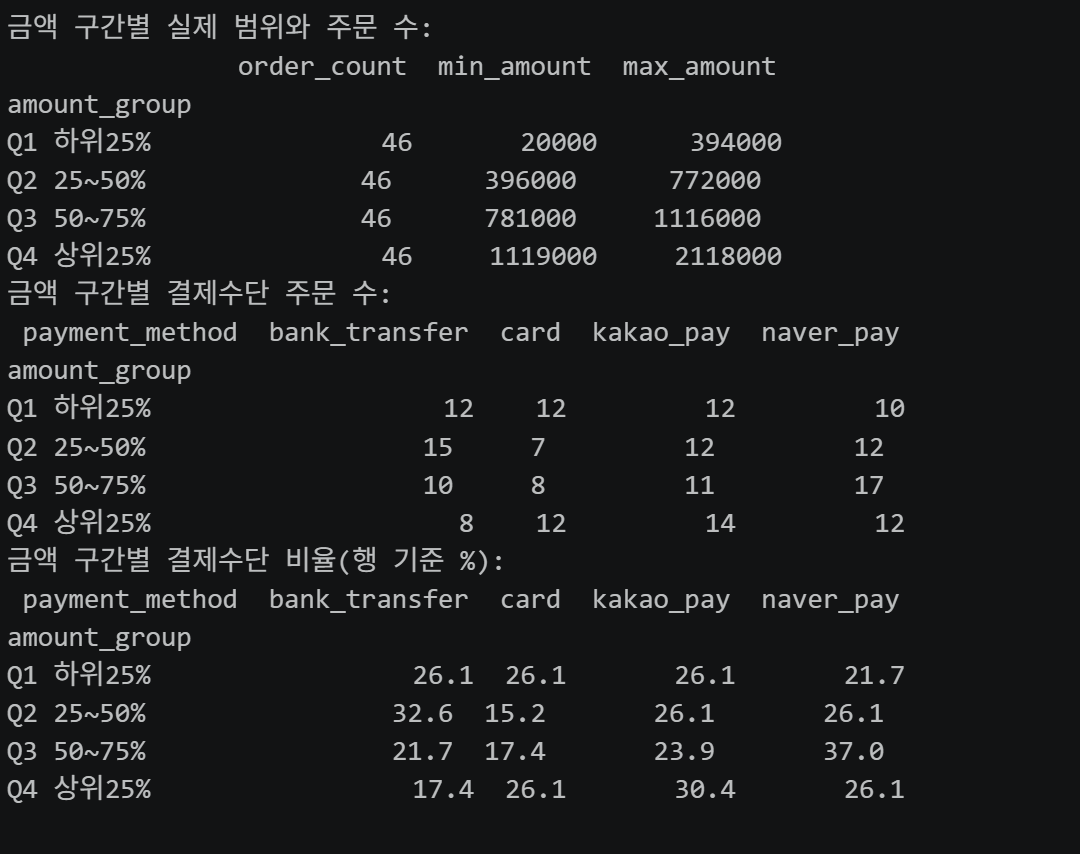

### 결과 관찰
연령대별로 보면 30대가 37,992,000원(25.50%)으로 가장 높은 비중을 차지했고, 20대 35,906,000원(24.10%), 60대 32,179,000원(21.60%) 순이었다. 전체 등록 고객 1명당 금액도 30대가 약 115만 원으로 가장 높았고, 50대는 약 71만 원이었다. 다만 구매 고객 비율도 30대 75.76%, 50대 51.85%로 차이가 있었다. 연령대별 고객 금액의 Kruskal-Wallis 검정에서는 p=0.5473으로 나타났다.
주문 금액을 사분위수로 나누니 각 구간에 완료 주문이 46건씩 포함되었다. 세 번째 금액 구간에서는 `naver_pay`의 비율이 37.0%로, 첫 번째 구간의 21.7%보다 높았다. 하지만 결제수단과 주문 금액 구간에 대한 카이제곱 검정 결과는 p=0.6380이었다.
가입일은 2023년 9월부터 2026년 8월까지 36개월에 걸쳐 있었다. 이 중 2024년 7월에는 가입이 0건이었고, 2024년 8월, 2026년 1월, 2026년 8월에는 각각 8건으로 가장 많았다. 월별 건수의 합계는 150건이었다.

### 나의 해석과 판단
연령대별 금액은 차이가 있지만 이것이 연령에 따른 구매 성향의 차이 때문이라고 단정하기는 어렵다. 표본 수부터 다르고, 구매하지 않은 고객의 비율도 서로 다르기 때문이다. 실제로 10대 고객은 5명뿐이므로 다른 연령대와 동일한 수준으로 비교하기는 어렵다고 판단된다. Kruskal-Wallis 검정에서도 통계적으로 유의한 차이가 확인되지는 않았다.
결제수단도 특정 금액 구간에서 비율이 상대적으로 높게 나타나기는 했지만, 현재 데이터에서는 금액 구간과 결제수단 사이에 뚜렷한 관련성이 있다고 보기 어려웠다. 가입 건수 역시 월마다 차이가 있으나 마케팅이나 계절적 요인 때문인지 판단할 수는 없다.

### 업무·분석적 의미
연령대별 총금액과 1인당 금액을 구분하면 단순히 고객이 많은 집단인지, 실제로 고객 1명당 완료 주문 금액이 큰 집단인지 비교할 수 있다. 결제수단 분석은 고액 주문 고객에게 특정 결제수단을 우선 제공할 필요가 있는지 검토할 때 활용할 수 있지만, 이번 결과만으로 그런 차별화가 필요하다고 보기는 어렵다. 가입월 분포는 신규 고객 수의 변동을 확인하기 위한 출발점이 될 수 있다.

### 한계와 추가 확인 사항
여기서 사용하는 금액은 `completed` 주문의 `line_total` 합계로, 할인·배송비·수수료 등을 반영한 순매출은 아니다. 현재 고객의 나이를 사용했으므로 구매 당시의 정확한 연령대와 다를 수 있고, 가입 후 얼마 동안 구매 기회가 있었는지도 고려하지 않았다. 또한 전체 300개 주문 중 56건, completed 주문 중에서도 35건은 고객 가입일보다 주문일이 앞서 있었다. 따라서 가입 후 구매 전환이나 첫 구매 소요 기간은 날짜 기록의 의미를 먼저 확인한 뒤 분석해야 한다.

In [38]:
# 공통 검증: 주문 상세를 기준으로 계산한 금액과 그룹별 금액이 같아야 한다.
assert (order_items['line_total'] == order_items['quantity'] * order_items['unit_price']).all()
assert len(order_sales_all) == len(order_items)
assert order_sales_all['_merge'].eq('both').all()
assert len(sales_items) == len(completed_items)
assert sales_items['category'].notna().all()
assert len(completed_items) == len(order_sales)
assert int(category_sales.total_sales.sum()) == source_total
assert int(monthly_sales.total_sales.sum()) == source_total
assert int(customer_sales.total_sales.sum()) == source_total
print(f'원본 completed 합계  : {source_total:,}원')
print(f'카테고리 합계        : {category_sales.total_sales.sum():,.0f}원')
print(f'월별 합계            : {monthly_sales.total_sales.sum():,.0f}원')
print(f'고객별 합계          : {customer_sales.total_sales.sum():,.0f}원')
print('집계 총합 검증: 모두 일치')

원본 completed 합계  : 148,990,000원
카테고리 합계        : 148,990,000원
월별 합계            : 148,990,000원
고객별 합계          : 148,990,000원
집계 총합 검증: 모두 일치


## 3. 관찰 → 가설 → 추가 검증

### 사례 1
- 관찰: 30대의 completed 주문 금액은 37,992,000원으로 연령대 중 가장 높았고, 등록 고객 1명당 금액도 약 115만 원이었다. 반면 50대의 1인당 금액은 약 71만 원이었다.
- 가설: 30대에서 구매한 고객의 비율이 높거나, 구매 고객의 주문 횟수 및 주문당 금액이 상대적으로 높아서 차이가 나타났을 수 있다.
- 추가 검증: 연령대별 구매 고객 비율과 구매자당 금액, 완료 주문 횟수를 따로 계산해 비교하였다. 실제로 30대와 50대의 구매 고객 비율은 각각 75.76%, 51.85%였다. 연령대별 고객 수가 다르므로 이후에는 표본 수와 관측 기간도 함께 고려할 필요가 있다.

### 사례 2
- 관찰: 주문 금액의 세 번째 사분위 구간에서 `naver_pay` 비중이 37.0%였으나, 전체 구간과 결제수단의 독립성 검정은 p=0.6380이었다.
- 가설: 주문 금액이 높을수록 사용하는 결제수단이 달라질 수 있다고 생각했지만, 현재 관찰된 비율 차이는 우연한 표본 변동으로도 설명될 수 있다.
- 추가 검증: 완료 주문 184건을 금액 사분위수에 따라 나누고 결제수단별 비율과 카이제곱 통계량을 계산하였다. 기대빈도의 최솟값은 9.75로 확인되었다. 추후 데이터가 더 많아지면 금액을 연속형으로 두고도 같은 패턴이 나타나는지 확인해볼 수 있다.

### 사례 3
- 관찰: 가입 기록이 있는 기간은 36개월이며, 2024년 7월은 0건, 가장 많은 달은 8건이었다. 2024년 전체 가입은 49건, 2025년은 40건이었다.
- 가설: 고객 가입이 시기별로 고르게 발생하지 않았을 수 있다. 다만 실제 가입자 전체가 아니라 일부만 추출된 데이터라면 이 차이가 표본 추출 과정에서 나타났을 가능성도 있다.
- 추가 검증: 가입이 없는 월도 0건으로 포함하고 연도별 월수와 가입 건수를 비교하였다. 2023년은 9~12월, 2026년은 1~8월만 포함되어 있으므로 연도별 합계를 바로 비교하는 것은 적절하지 않다. 실제 서비스의 전체 가입 기록과 데이터 추출 기준이 확인되면 월별 증감을 다시 검토하고자 한다.

## 4. LLM 질문 확장


- Safe Context: `customers(150행)`, `products(100행)`, `orders(300행)`, `order_items(764행)`의 컬럼 구조와 주문 상태별 건수(`completed` 184건, `cancelled` 64건, `refunded` 52건), 완료 주문 기준 합계 148,990,000원만 사용하였다. 고객 이름이나 개별 주문 내역은 포함하지 않았다.
- Prompt: "온라인 쇼핑몰 고객·상품·주문·주문 상세 데이터가 있다. 현재 질문은 연령대별 완료 주문 금액, 주문 금액별 결제수단, 월별 가입 건수이다. 금액은 completed 주문의 `line_total`만 사용한다. 현재 컬럼으로 검증 가능한 후속 EDA 질문 3개와 각 질문에 필요한 지표를 제안해줘. 데이터에 없는 원인은 단정하지 말아줘."
- LLM 제안 요약:
  1. 연령대별 금액 차이는 구매 고객 비율과 구매자당 금액 중 어느 쪽과 더 관련이 있는가? → 고객 수, 완료 주문 구매 고객 수, 구매자당 금액으로 확인 가능하다.
  2. 결제수단별 주문 완료 비율도 서로 다른가? → 모든 주문의 `payment_method`, `order_status`가 있어 추가 집계가 가능하다.
  3. 고객이 가입한 뒤 첫 구매까지 걸린 기간은 연령대별로 다른가? → 날짜 컬럼은 있지만 가입일보다 앞선 주문이 존재해 바로 해석하기 어렵다.
- 실제 사용 여부: 수정 후 사용. 첫 번째 질문은 연령대별 분석에 추가하여 계산했고, 두 번째는 다음 분석 후보로 남겼다. 세 번째는 날짜의 의미를 확인할 때까지 보류하였다.
- 판단 이유: 첫 번째는 현재 데이터로 계산할 수 있고, 단순 금액 비교에서 확인하지 못한 구매 고객 비율을 함께 볼 수 있기 때문이다. 반면 세 번째는 가입일 이전의 completed 주문이 35건 존재해 그대로 계산하면 음수 기간이 나올 수 있다.
- 사람이 수정한 내용: '연령대별 매출'을 회계상 매출이 아닌 연령대별 completed 주문 금액으로 범위를 좁혔고, 평균의 분모를 전체 등록 고객과 실제 구매 고객으로 나누었다. 첫 구매까지 걸린 시간은 날짜 검증 없이 결론을 내리지 않도록 제외하였다.

## 5. 다음 분석 우선순위
1. 연령대별 금액 차이를 구매 고객 비율, 구매자당 평균 금액, 주문 횟수로 나눠 비교한다.
2. 결제수단별 완료·취소·환불 비율을 확인하고, 주문 금액 분포와 함께 해석한다.
3. 고객 가입일보다 주문일이 빠른 기록의 원인을 확인한 후 가입 시점과 구매 행동의 관계를 살펴본다.

### 가장 먼저 확인하고 싶은 이유
30대와 50대의 등록 고객 1명당 금액 차이는 꽤 컸지만, 이것만으로 고객의 구매 성향이 다르다고 설명할 수는 없다고 생각한다. 실제로 구매한 고객의 비율 자체도 다르므로 구매 여부와 구매 금액을 구분하는 것이 먼저일 것으로 보인다. 이번 노트북에서는 그 구분까지 계산하였으며, 이후에는 주문 횟수와 상품 구성도 함께 확인할 필요가 있다.

### 현재 데이터만으로 단정할 수 없는 것
연령대가 구매 금액에 직접적인 영향을 주는지, 특정 결제수단이 고액 주문에 선호되는지, 어떤 이유로 가입자 수가 변했는지는 알 수 없다. 프로모션이나 광고 노출, 결제 할인, 실제 전체 고객 모집단에 대한 정보가 없기 때문이다. 또한 가입일과 주문일이 맞지 않는 기록이 존재하므로 가입 이후의 구매 전환율을 그대로 계산하기는 어렵다. 현재 단계에서는 계산된 차이를 관찰한 결과로 남기고 원인에 대한 판단은 추가 검증이 필요하다고 생각한다.

In [39]:
# 다음 장에서 다시 활용할 수 있도록 개인정보 없는 요약표만 저장한다.
age_sales.to_csv(REPORT_DIR/'ch06_age_group_sales.csv',index=False,encoding='utf-8-sig')
payment_amount_counts.to_csv(REPORT_DIR/'ch06_payment_by_amount_count.csv',encoding='utf-8-sig')
payment_amount_ratio.to_csv(REPORT_DIR/'ch06_payment_by_amount_ratio.csv',encoding='utf-8-sig')
signup_monthly.to_csv(REPORT_DIR/'ch06_monthly_signups.csv',index=False,encoding='utf-8-sig')
print('과제 질문별 검증 결과 저장 완료:', REPORT_DIR)

과제 질문별 검증 결과 저장 완료: /mnt/data/reports


## 최종 체크
- [V] 질문과 지표가 연결되어 있습니다.
- [V] 집계 총합을 검증했습니다.
- [V] 관찰과 가설을 구분했습니다.
- [V] 다음 검증 질문을 작성했습니다.
- [V] LLM 제안을 실제 컬럼과 데이터 범위에 맞춰 검토했습니다.
- [V] 최종 Notebook URL을 입력할 항목을 남겼습니다. (GitHub 업로드 및 실제 URL 입력은 제출할 때 진행)